# T44–T45 · Demanda por estación y estado de carga

**Pregunta.** Con las ubicaciones, los viajes atendidos y los recursos de movilidad fijados, ¿cómo cambian la necesidad de recarga y el estado de la flota al usar cada modelo?

El ajuste comprende del 1 al 21 de febrero y la reserva del 22 al 28. Se distingue energía del conjunto observado, demanda de los viajes atendidos y tracción de la flota con batería simulada. T44 usa las devoluciones de T39 tras comprobarlas con T31. El supuesto de recarga es reponer la energía donde se deja el patinete.

In [1]:
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from ajustes import cargar_ajustes
from analisis_fisico import TABLAS
from agregados import publicar_agregados
from estado_carga import publicar_soc
from comun.figuras import guardar_figura, plt
from comun.web import exportar

v, resumen, estaciones, perfiles, sensibilidad, conciliacion, ranking = publicar_agregados()
p = cargar_ajustes()["analisis"]
habitual = resumen.loc[resumen["red"].eq(p["red_diseno"])]
f = pd.read_csv(TABLAS / "T43_calibracion.csv")
desnivel = pd.read_csv(TABLAS / "T42_desnivel.csv")

## T44 · Sumas y potencia por estación

La vista observada suma por ID de patinete y día de salida. La vista simulada usa solo devoluciones atendidas. Todos los Wh de esas devoluciones se asignan al destino simulado. La conciliación expone el número y los Wh de los viajes sin devolución asignada en cada red y periodo. Se verifica la igualdad de las sumas por viaje, patinete, estación e integración de potencia.

El P95 diario por estación incluye días sin devoluciones. Los perfiles de potencia incluyen los intervalos con cero demanda para el P95. Cada sesión de reposición usa la potencia nominal en batería y se integra por solape en periodos de 15 minutos y una hora. Se conserva la cola de una sesión que sobrepase el cierre del periodo. La etiqueta ajuste/reservada sigue al día de salida de la solicitud. El perfil medio web usa los días naturales del periodo y evita alterar el denominador por colas de fin de mes. La comparación entre redes se repite sobre sus viajes comunes para fijar la energía total de cada modelo.

Se escoge con el ajuste la estación de máximo consumo del Modelo A para inspeccionar su perfil en los dos periodos. También se publican por separado las estaciones máximas por energía y por potencia de cada modelo.

,red,periodo,modelo,viajes,estaciones,kwh,kwh_dia,pico_red_w,estacion_energia_max,energia_max_kwh,estacion_pico_max,pico_estacion_w,top_pct,periodo_desde,intervalos_15min
4,habitual,ajuste,a,12750,159,349.535,16.645,3377.138,891e8052a6bffff,6.498,891e8051d07ffff,448.073,15.371,2021-02-01,2020
5,habitual,ajuste,b,12750,159,348.524,16.596,3190.169,891e8052a23ffff,6.791,891e8052a6bffff,438.857,14.720,2021-02-01,2020
6,habitual,reservada,a,4670,159,131.301,18.757,3464.569,891e8052a6bffff,3.002,891e8051d07ffff,481.630,16.819,2021-02-22,672
7,habitual,reservada,b,4670,159,131.261,18.752,2863.658,891e8052a23ffff,3.162,891e8052a6bffff,408.151,16.392,2021-02-22,672


,red,periodo,modelo,observados,atendidos,sin_destino_en_red,observados_wh,atendidos_wh,sin_destino_wh,patinetes_wh,estaciones_wh,diferencia_wh
4,habitual,ajuste,a,16756,12750,4006,464812.863743,349534.626726,115278.237017,349534.626726,349534.626726,0
5,habitual,ajuste,b,16756,12750,4006,464812.863735,348523.915556,116288.948179,348523.915556,348523.915556,0
6,habitual,reservada,a,6614,4670,1944,190398.735026,131301.309785,59097.425241,131301.309785,131301.309785,0
7,habitual,reservada,b,6614,4670,1944,190921.632366,131260.985927,59660.646440,131260.985927,131260.985927,0


,red,periodo,spearman,estaciones_pico_b_mayor,mayor_aumento_pico_b_w,comunes_top
0,equidad,ajuste,0.933,57,82.286,8
1,equidad,reservada,0.937,39,59.108,6
2,habitual,ajuste,0.937,55,56.320,8
3,habitual,reservada,0.935,38,59.108,7
4,redundante,ajuste,0.929,49,56.320,7
5,redundante,reservada,0.929,41,75.611,7


,periodo,red,modelo,viajes,kwh,top_pct,estacion_max,estacion_max_kwh
0,ajuste,equidad,a,12261,336.309,15.584,891e8052a6bffff,6.436
1,ajuste,equidad,b,12261,335.595,14.958,891e8052a23ffff,6.598
2,ajuste,habitual,a,12261,336.309,15.692,891e8052a6bffff,6.436
3,ajuste,habitual,b,12261,335.595,15.051,891e8052a23ffff,6.655
4,ajuste,redundante,a,12261,336.309,15.485,891e8052a6bffff,6.564
5,ajuste,redundante,b,12261,335.595,15.190,891e8052a23ffff,6.608
6,reservada,equidad,a,4414,124.431,16.905,891e8052a6bffff,2.916
7,reservada,equidad,b,4414,124.575,16.396,891e8052a23ffff,2.978
8,reservada,habitual,a,4414,124.431,16.896,891e8050cd3ffff,2.893
9,reservada,habitual,b,4414,124.575,16.391,891e8052a23ffff,2.978


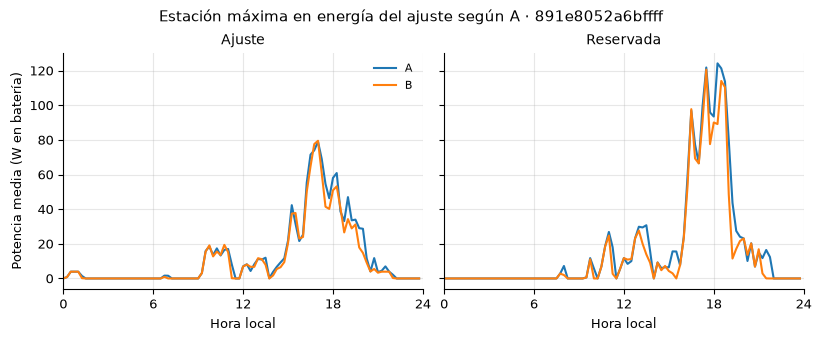

In [2]:
display(habitual.round(3))
display(conciliacion.loc[conciliacion["red"].eq(p["red_diseno"])].round(6))
display(ranking.round(3), sensibilidad.round(3))
critica = habitual.query("periodo == 'ajuste' and modelo == 'a'")["estacion_energia_max"].iloc[0]
n = 24 * 60 // p["paso_perfil_min"]
reloj = np.arange(n) * p["paso_perfil_min"] / 60
perfil = perfiles.loc[perfiles["red"].eq(p["red_diseno"])]
fig, ejes = plt.subplots(1, 2, figsize=(8.1, 3.3), sharey=True, layout="constrained")
for eje, (periodo, g) in zip(ejes, perfil.loc[perfil["station_id"].eq(critica)].groupby("periodo")):
    for modelo, m in g.groupby("modelo"):
        eje.plot(reloj, m.set_index("intervalo")["potencia_w"].reindex(range(n), fill_value=0), label=modelo.upper())
    eje.set(title=periodo.capitalize(), xlabel="Hora local", xticks=[0, 6, 12, 18, 24], xlim=(0,24))
ejes[0].set_ylabel("Potencia media (W en batería)")
ejes[0].legend(frameon=False)
fig.suptitle("Estación máxima en energía del ajuste según A · " + critica)
guardar_figura(fig, "consumo", "T44_perfil_estacion")

## T45 · Estado de carga durante el mes

Se reutilizan la flota, la reserva y la regla de carga de T35. Las unidades simuladas mantienen su identidad dentro de todo febrero y el estado pasa de ajuste a reserva. Un control separado repite cada periodo reiniciando la flota para comprobar la comparación con T35. La energía del viaje se descuenta al salir y el anclaje recupera energía linealmente cuando la unidad está estacionada. La traza registra salida, llegada, recolocación y cierre. El mínimo diario se calcula desde el arranque del día y los eventos, incluso si un vehículo viaja durante la medianoche. El ID de unidad simulada es independiente de los identificadores de patinetes observados.

,periodo,modelo,flota,reserva_pct,solicitudes,atendidos,rechazos_bateria,unidades_bajo_reserva,min_soc_pct,mediana_min_unidad_pct,traccion_kwh
0,ajuste,a,400,20.0,16756,12750,0,0,54.860,83.265,349.535
1,reservada,a,400,20.0,6614,4664,0,0,38.915,87.869,131.079
2,ajuste,b,400,20.0,16756,12750,0,0,56.024,82.644,348.524
3,reservada,b,400,20.0,6614,4664,0,0,36.637,86.853,131.018


,modelo,periodo,atendidos,rechazos_bateria
0,a,ajuste,12750,0
1,a,reservada,4670,0
2,b,ajuste,12750,0
3,b,reservada,4670,0


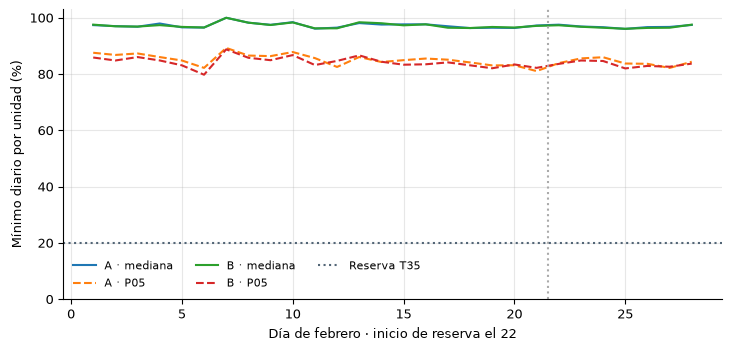

In [3]:
soc, diario = publicar_soc(v)
display(soc.round(3), pd.read_csv(TABLAS / "T45_control_t35.csv"))
fig, ax = plt.subplots(figsize=(7.2, 3.4), layout="constrained")
for modelo, g in diario.groupby("modelo"):
    dia = pd.to_datetime(g["fecha"]).dt.day
    ax.plot(dia, g["mediana"], label=f"{modelo.upper()} · mediana")
    ax.plot(dia, g["p05"], "--", label=f"{modelo.upper()} · P05")
ax.axvline(21.5, color="#aaa", ls=":")
ax.axhline(soc["reserva_pct"].iloc[0], color="#526576", ls=":", label="Reserva T35")
ax.set(xlabel="Día de febrero · inicio de reserva el 22", ylabel="Mínimo diario por unidad (%)", ylim=(0, 103))
ax.legend(frameon=False, ncol=3)
guardar_figura(fig, "consumo", "T45_soc")

## Datos de la web

Los controles de periodo usan la misma separación que los notebooks. Los perfiles elegibles resuelven la selección de estación desde el ajuste y rellenan con cero los intervalos sin carga. Se publica la dispersión por viaje como recuento de una cuadrícula común y se conservan los CSV completos.

In [4]:
perfiles_web = []
ubicaciones = estaciones.loc[estaciones["red"].eq(p["red_diseno"]), "station_id"].unique()
for periodo in habitual["periodo"].unique():
    g = perfil.loc[perfil["periodo"].eq(periodo)]
    for station_id in ubicaciones:
        e = g.loc[g["station_id"].eq(station_id)]
        perfiles_web.append({"periodo": periodo, "station_id": station_id, **{
            m: e.loc[e["modelo"].eq(m)].set_index("intervalo")["potencia_w"].reindex(range(n), fill_value=0).round(4).tolist()
            for m in ("a", "b")}})
z = []
b = np.histogram_bin_edges(v["desnivel_m"], bins=40)
bordes_energia = np.linspace(0, max(v["energia_wh_a"].max(), v["energia_wh_b"].max()), 25)
for periodo, g in v.groupby("periodo"):
    hist, _, _ = np.histogram2d(g["energia_wh_a"], g["energia_wh_b"], bins=[bordes_energia, bordes_energia])
    z.append({"periodo": periodo, "centros_m": (b[1:]+b[:-1])/2, "cuentas": np.histogram(g["desnivel_m"], bins=b)[0],
              "centros_wh": (bordes_energia[1:]+bordes_energia[:-1])/2, "densidad": hist.T.astype(int)})
exportar("fase2", "consumo", {
    "fisico": f, "desnivel": desnivel, "histogramas": z, "resumen": habitual, "conciliacion": conciliacion.loc[conciliacion["red"].eq(p["red_diseno"])],
    "ranking": ranking.loc[ranking["red"].eq(p["red_diseno"])], "soc": soc, "diario": diario,
    "sensibilidad": sensibilidad, "estacion_inicial": critica, "n_top": p["top_concentracion"],
    "observado_diario": pd.read_csv(TABLAS / "T44_observado_flota_dia.csv"),
})
exportar("fase2", "perfiles", {"minutos": np.arange(n)*p["paso_perfil_min"], "perfiles": perfiles_web})

In [5]:
a, b = (habitual.query("periodo == 'reservada' and modelo == @m").iloc[0] for m in ("a", "b"))
sa, sb = (soc.query("periodo == 'reservada' and modelo == @m").iloc[0] for m in ("a", "b"))
display(Markdown(f"""## Conclusiones
- En reserva, los mismos **{a.viajes:,}** viajes atendidos requieren **{a.kwh_dia:.2f} frente a {b.kwh_dia:.2f} kWh/día**. La estación máxima por energía cambia de **{a.estacion_energia_max}** a **{b.estacion_energia_max}**.
- El pico simultáneo cambia de **{a.pico_red_w/1000:.2f} a {b.pico_red_w/1000:.2f} kW**. Se conserva A como referencia normativa y B como sensibilidad espacial; cada estación se coteja con ambos.
- Con continuidad de inventario y una reserva de **{sa.reserva_pct:.0f} %**, los mínimos en la semana reservada son **{sa.min_soc_pct:.2f} %** con A y **{sb.min_soc_pct:.2f} %** con B. Los rechazos por batería son **{sa.rechazos_bateria} y {sb.rechazos_bateria}**.""".replace(f"{a.viajes:,}", f"{a.viajes:,}".replace(",", " "))))

## Conclusiones
- En reserva, los mismos **4 670** viajes atendidos requieren **18.76 frente a 18.75 kWh/día**. La estación máxima por energía cambia de **891e8052a6bffff** a **891e8052a23ffff**.
- El pico simultáneo cambia de **3.46 a 2.86 kW**. Se conserva A como referencia normativa y B como sensibilidad espacial; cada estación se coteja con ambos.
- Con continuidad de inventario y una reserva de **20 %**, los mínimos en la semana reservada son **38.92 %** con A y **36.64 %** con B. Los rechazos por batería son **0 y 0**.